# Entity matching: estimating the parameters without labels

We have a table of 50,000 known companies and 20,000 incoming records
("queries"). For each query we want to know which company it refers to, or
that it refers to none of them. The method is written up in
[`docs/methods.md`](docs/methods.md); this notebook runs it end to end and
checks every step against the answer key.

## The idea in one paragraph

Compare a query to a candidate company one attribute at a time. For each
attribute, ask two questions: **how often do true matches look like this?**
(call it `m`) and **how often do non-matches look like this by coincidence?**
(call it `u`). The ratio `m / u` says how much that piece of evidence is
worth. Take the log, add the pieces up, and you have a score. Agreeing on a
rare phone number is strong evidence because `m` is high and `u` is tiny.
Agreeing on a shared office address is weak evidence because `u` is also
high. This is the Fellegi-Sunter model.

## The vocabulary

| Term | What it means |
|---|---|
| **attribute** | name, address, phone, email, website or tax id |
| **comparison level** | how a query and a company compare on one attribute: `0` = one side is missing it, `1` = they disagree, `2+` = increasing agreement, top level = identical |
| **m** | P(this level \| the pair really is a match). High for reliable attributes |
| **u** | P(this level \| the pair is not a match). The coincidence rate |
| **weight** | `log2(m / u)` for the observed level, in bits. Positive = evidence for, negative = evidence against |
| **bit** | a factor of 2. +10 bits means the evidence is ~1,000x more likely under a match; +20 bits, ~1,000,000x |
| **score** | the weights added up across attributes. A missing attribute contributes 0 |
| **candidate** | a company worth scoring against this query, found by blocking |
| **blocking** | the cheap filter that avoids scoring all 50,000 x 20,000 pairs |
| **N** | number of known companies (50,000) |
| **rho** | share of queries whose company is actually in the table |

## Why this notebook exists

`m` and `u` are the whole model, and in real work nobody hands them to you.
Estimating them from unlabeled data is where the method is won or lost. Each
step below has an obvious default that looks reasonable and is quietly wrong.
Because this dataset is synthetic we have the true answers, so we can run the
unlabeled estimator, run the obvious default, and show both against the truth.

| Step | What we estimate | How, without labels | The default that fails |
|---|---|---|---|
| 4 | `u`: P(level \| non-match) | compare known-distinct companies to each other | random query-company pairs |
| 5 | `m`: P(level \| match) | one EM run per blocking rule, `u` held fixed | one EM run over all candidates |
| 6 | value-specific `u` | `(count - 1) / N`, with a floor | `count / N` |
| 8 | match probability | normalize over all companies, per query | score each pair on its own |

The data comes from `generate_data.py` (50,000 companies, 20,000 queries, 15%
of which refer to no company in the table). The library is `matching.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import matching as mt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
ATTRS = [c.attr for c in mt.COMPARISONS]

E = pd.read_csv("data/entities.csv")
Q = pd.read_csv("data/queries.csv")
T = pd.read_csv("data/truth.csv")
N, NQ = E.entity_id.nunique(), Q.query_id.nunique()
print(f"{N:,} entities / {len(E):,} rows; {NQ:,} queries / {len(Q):,} rows")
print(f"queries with a true match in the table: {T.entity_id.notna().mean():.1%}")

50,000 entities / 211,551 rows; 20,000 queries / 59,020 rows
queries with a true match in the table: 85.0%


## 1. What the data looks like

Both tables are in long format: one row per `(id, attribute, value)`, so a
company with four attributes takes four rows. Companies have between 1 and 10
attributes.

Two things to read off the table below:

- **Coverage is uneven.** Every company has a name, but only ~40% have a tax
  id. This is why a missing attribute has to count as *nothing* rather than as
  disagreement — otherwise every company without a tax id would be penalized
  for a gap in our records.
- **Values are shared.** `max_entities_per_value` is the worst case per
  attribute.

In [2]:
per = E.groupby("entity_id").size()
print("attributes per entity:", per.describe()[["min", "50%", "max"]].to_dict())
cov = E.groupby("attr_type").entity_id.nunique().div(N).rename("entity_coverage")
qcov = Q.groupby("attr_type").query_id.nunique().div(NQ).rename("query_coverage")
shared = (E.groupby(["attr_type", "value"]).entity_id.nunique()
          .groupby("attr_type").agg(max_entities_per_value="max"))
pd.concat([cov, qcov, shared], axis=1).round(3)

attributes per entity: {'min': 1.0, '50%': 4.0, 'max': 10.0}


,entity_coverage,query_coverage,max_entities_per_value
attr_type,,,
address,0.901,0.704,242
email,0.424,0.262,2
name,1.000,0.923,4
phone,0.769,0.606,106
tax_id,0.399,0.202,1
website,0.421,0.213,3


One address is used by ~240 companies (a registered-agent office) and one
phone by ~100 (an answering service). Agreeing on *those* values is nearly
worthless, while agreeing on a one-off address is strong evidence. A single
`u` per attribute cannot say both things at once, which is the problem step 6
solves.

## 2. Normalize

Before anything is compared, values are put in a standard form: names are
lower-cased with punctuation and legal suffixes (Inc, LLC, Corp) removed,
phones are reduced to ten digits, websites lose `https://` and `www.`, and
addresses lose their suite numbers and get standard street abbreviations.

Dropping suite numbers is a deliberate choice, not an oversight. It means
every tenant of a building ends up with the same normalized address, which is
what lets us find them — and it is exactly why step 6 is needed to stop that
agreement from counting for too much.

Everything downstream depends on this step, so it is worth eyeballing.

In [3]:
e = mt.normalize(E, "entity_id")
q = mt.normalize(Q, "query_id")
tf = mt.value_tf(e)
Q.head(6).assign(norm=q.head(6).norm.values)

,query_id,attr_type,value,norm
0,Q000000,name,Ostcorbri Marketing Company,ostcorbri marketing
1,Q000000,address,"71 Mowexmar Ave, Chicago, IL 60606",71 mowexmar ave chicago il 60606
2,Q000000,phone,(801) 852-9988,8018529988
3,Q000000,email,kpatel@ostcorbrimarketing.com,kpatel@ostcorbrimarketing.com
4,Q000001,name,Brihel Sola rCorp,brihel sola rcorp
5,Q000001,phone,6089436325,6089436325


## 3. Blocking and comparison vectors

Scoring all 20,000 x 50,000 = 1 billion pairs would be wasteful, and nearly
all of them are obvious non-matches. **Blocking** picks the pairs worth
scoring. A company becomes a candidate for a query if they share either:

1. an exact normalized value on any attribute, or
2. a rare name token — one held by 30 companies or fewer. This catches
   "Acme Widgets Inc" vs "Acme Widgets LLC" and single typos, as long as one
   unusual word survives intact.

Blocking recall is a hard ceiling on everything that follows. A true match
that never becomes a candidate cannot be recovered by any amount of clever
scoring later, so it is the first number to check.

`mt.compare` then turns each candidate pair into a **comparison vector**: one
level per attribute, describing how the two sides line up.

In [4]:
cand = pd.concat([mt.block_exact(q, e, ATTRS), mt.block_name_tokens(q, e)]).drop_duplicates()
truth = T.dropna(subset=["entity_id"]).rename(columns={"query_id": "qid", "entity_id": "eid"})
recall = truth.merge(cand, on=["qid", "eid"]).shape[0] / len(truth)
print(f"candidate pairs: {len(cand):,} ({len(cand) / NQ:.1f} per query)")
print(f"blocking recall: {recall:.1%}")

L = mt.compare(cand, q, e, tf)
L.head()

candidate pairs: 274,180 (13.7 per query)
blocking recall: 97.8%


,qid,eid,name,tf_name,address,tf_address,phone,tf_phone,email,tf_email,website,tf_website,tax_id,tf_tax_id
0,Q000000,E024795,4,0.00002,3,0.00002,2,0.00002,0,NaN,0,NaN,0,NaN
1,Q000002,E001005,4,0.00004,1,NaN,0,NaN,0,NaN,0,NaN,0,NaN
2,Q000002,E008908,4,0.00004,2,NaN,2,0.00002,0,NaN,0,NaN,0,NaN
3,Q000004,E021160,4,0.00002,3,0.00002,0,NaN,0,NaN,0,NaN,0,NaN
4,Q000005,E000216,4,0.00002,0,NaN,0,NaN,0,NaN,0,NaN,0,NaN


Reading the table above: each attribute column holds a level code, where `0`
means one side is missing the attribute, `1` means the two sides disagree, and
higher numbers mean stronger agreement up to exact equality. Name has 5 levels
(the middle two are Jaro-Winkler similarity bands), address has 4, and the
rest have 3. `mt.COMPARISONS` holds the labels. The `tf_<attr>` columns record
how common the agreeing value is; step 6 uses them.

### The answer key

The next cell builds the reference values we will grade against. **You will
not have these on real data** — they exist here only so each unlabeled
estimate can be checked:

- `m_true`: `m` computed from the true matching pairs.
- `u_true`: `u` computed from random query-company pairs with the true matches
  removed.

It also builds `RQ`, a million random query-company pairs *without* removing
the true matches. That is the naive way to estimate `u`, and step 4 shows what
it costs.

In [5]:
TL = mt.compare(truth[["qid", "eid"]], q, e, tf)
m_true = mt.level_dist(TL)

rng = np.random.default_rng(0)
RQ = pd.DataFrame({"qid": rng.choice(q.id.unique(), 1_000_000),
                   "eid": rng.choice(e.id.unique(), 1_000_000)}).drop_duplicates()
RQ = mt.compare(RQ, q, e, tf)
is_match = RQ.merge(truth[["qid", "eid"]].assign(hit=1), on=["qid", "eid"], how="left")["hit"].notna().values
u_true = mt.level_dist(RQ[~is_match])
print(f"true matches inside 1M 'random' query-entity pairs: {is_match.sum()}")

true matches inside 1M 'random' query-entity pairs: 21


## 4. Estimate u

`u` is the coincidence rate: how often a pair that is *not* a match still
agrees on an attribute. It looks like the easy parameter, because almost any
random pair of records is a non-match. "Almost" is the catch.

The share of random query-company pairs that are secretly true matches is
about rho/N, which is roughly 1.7e-5 here. For a discriminating level such as
*exact name*, the true coincidence rate is about 2e-6 — **smaller than the
contamination rate**. A handful of real matches hiding in the sample then
dominates the estimate and inflates `u` exactly where accurate values matter
most.

The fix: if the company table has been deduplicated, then any two *distinct*
companies are a non-match by construction. No contamination, no labels needed.

The trade-off is that company records are cleaner than query records — no
typos — so this understates `u` for the fuzzy "nearly agrees" levels. Step 7
deals with that.

In [6]:
a_, b_ = rng.choice(e.id.unique(), 2_000_000), rng.choice(e.id.unique(), 2_000_000)
EE = mt.compare(pd.DataFrame({"qid": a_[a_ != b_], "eid": b_[a_ != b_]}).drop_duplicates(), e, e, tf)
u = mt.level_dist(EE)
u_contaminated = mt.level_dist(RQ)

rows = []
for c in mt.COMPARISONS:
    top = c.n_levels - 1
    rows.append({"attr": c.attr, "level": c.labels[top], "u_labeled": u_true[c.attr][top],
                 "u_random_query_pairs": u_contaminated[c.attr][top], "u_entity_pairs": u[c.attr][top]})
pd.DataFrame(rows).set_index("attr").style.format(
    "{:.2e}", subset=["u_labeled", "u_random_query_pairs", "u_entity_pairs"])

,level,u_labeled,u_random_query_pairs,u_entity_pairs
attr,,,,
name,exact,2.17e-06,2.17e-05,2.50e-06
address,exact,8.99e-05,1.04e-04,9.19e-05
phone,agree,6.44e-06,1.72e-05,2.62e-05
email,agree,9.00e-06,5.40e-05,2.78e-06
website,agree,1.12e-05,2.24e-05,8.48e-06
tax_id,agree,1.24e-05,4.98e-05,3.15e-06


Compare the last two columns against `u_labeled`. Random query pairs overstate
`u` by about 10x for name, 6x for email and 4x for tax id — and those are
precisely the attributes whose high weights carry the match. The excess is the
21 true matches sitting in the sample. Company-vs-company pairs avoid it.

Address is fine either way, because its `u` is driven by genuinely shared
buildings rather than by contamination. For phone, company pairs *overstate*
`u` (a company record carries more phone numbers than a query does), which
errs in the safe direction.

**A limit that labels do not fix.** For name, email, website and tax id,
distinct companies essentially never agree, so the counts behind these numbers
are 0 to 4 agreements out of two million pairs. The estimate is then pinned near the
pseudo-count floor of `1 / (number of non-null pairs)`, which means it is
reporting our sample size rather than measuring anything. Doubling the sample
would add about one bit to the top weight. The query-level posterior in step 8
limits the damage, but a candidate supported by one of these attributes alone
should be treated as less certain than its score suggests.

## 5. Estimate m with EM

`m` is the opposite problem. It is the rate at which *true matches* show each
level, so estimating it needs a pool of pairs with plenty of real matches in
it — and the only such pool is the candidate set.

Since we have no labels, we use **expectation-maximization**. EM handles
exactly this situation: we believe the candidate pairs are a mixture of
matches and non-matches, but we cannot see which is which. So we guess the
mixture, use the guess to assign each pair a probability of being a match,
re-estimate the mixture from those probabilities, and repeat until it settles:

1. **E-step** — given current `m`, `u` and lambda (the share of matches), work
   out each pair's probability of being a match.
2. **M-step** — recompute `m` and lambda, counting each pair in proportion to
   that probability.

Throughout, `u` is held fixed at the step-4 values. We already have a clean
estimate of it and we do not want EM to drift it around.

### 5a. The obvious approach, and why it breaks

In [7]:
naive = mt.em(L, u, ATTRS)
print(f"naive EM: lambda = {naive.lam:.3f}, iterations = {naive.n_iter}")
pd.DataFrame({a: {"m_agree_naive": naive.m[a][-1], "m_agree_true": m_true[a][-1]} for a in ATTRS}).T.round(3)

naive EM: lambda = 0.688, iterations = 152


,m_agree_naive,m_agree_true
name,0.086,0.904
address,0.424,0.852
phone,0.116,0.730
email,0.091,0.830
website,0.138,1.000
tax_id,0.101,0.984


Those `m_agree` values are badly wrong, and the reason is worth understanding
because it is easy to walk into.

Every candidate pair is a candidate *because* it agrees on some blocking
value. Meanwhile `u` says such agreement is vanishingly rare among
non-matches. Put those together and EM concludes that almost every candidate
is a match — lambda shoots up. The non-matches dragged in by a shared office
address are now labelled "matches", and they disagree on everything else, so
`m` for agreement on the other attributes collapses toward 0.

The model is being told "these pairs were selected for agreeing" and has no
way to know it.

### 5b. The fix: one EM run per blocking rule, leaving that rule's attribute out

Inside the set of pairs blocked on exact name, every pair agrees on name, so
name carries no information about which of them are matches. Drop it from the
likelihood and estimate the others. Then do the same for pairs blocked on
phone, dropping phone.

The requirement is that each attribute gets estimated in at least one round
where it was *not* the thing used for selection. Blocking on name and on phone
is enough to cover all six attributes here. Attributes estimated in both
rounds take the average. (This is how Splink does it.)

In [8]:
pairs_name = L.merge(mt.block_exact(q, e, ["name"]), on=["qid", "eid"])
pairs_phone = L.merge(mt.block_exact(q, e, ["phone"]), on=["qid", "eid"])
r_name = mt.em(pairs_name, u, [a for a in ATTRS if a != "name"])
r_phone = mt.em(pairs_phone, u, [a for a in ATTRS if a != "phone"])
print(f"round blocked on name : {len(pairs_name):,} pairs, lambda {r_name.lam:.3f}, {r_name.n_iter} iters")
print(f"round blocked on phone: {len(pairs_phone):,} pairs, lambda {r_phone.lam:.3f}, {r_phone.n_iter} iters")

m = {}
for a in ATTRS:
    ests = [r.m[a] for r in (r_name, r_phone) if a in r.m]
    m[a] = np.mean(ests, axis=0)

cmp_rows = []
for c in mt.COMPARISONS:
    for lv in range(1, c.n_levels):
        cmp_rows.append({"attr": c.attr, "level": c.labels[lv], "m_true": m_true[c.attr][lv],
                         "em_name_round": r_name.m.get(c.attr, [np.nan] * c.n_levels)[lv],
                         "em_phone_round": r_phone.m.get(c.attr, [np.nan] * c.n_levels)[lv],
                         "em_combined": m[c.attr][lv], "naive": naive.m[c.attr][lv]})
mcmp = pd.DataFrame(cmp_rows)
mcmp.round(3)

round blocked on name : 15,785 pairs, lambda 0.900, 26 iters
round blocked on phone: 10,601 pairs, lambda 0.546, 9 iters


,attr,level,m_true,em_name_round,em_phone_round,em_combined,naive
0,name,none,0.020,NaN,0.020,0.020,0.756
1,name,jw>=0.85,0.007,NaN,0.007,0.007,0.150
2,name,jw>=0.94,0.070,NaN,0.070,0.070,0.007
3,name,exact,0.904,NaN,0.903,0.903,0.086
4,address,disagree,0.104,0.099,0.026,0.063,0.573
5,address,lev>=0.90,0.044,0.045,0.047,0.046,0.003
6,address,exact,0.852,0.856,0.927,0.891,0.424
7,phone,disagree,0.270,0.263,NaN,0.263,0.884
8,phone,agree,0.730,0.737,NaN,0.737,0.116
9,email,disagree,0.170,0.170,0.176,0.173,0.909


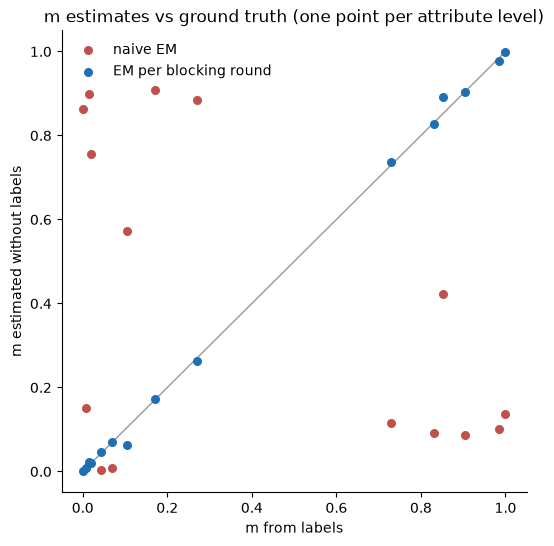

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], color="#999", lw=1, zorder=0)
ax.scatter(mcmp.m_true, mcmp.naive, label="naive EM", color="#c0504d", s=30)
ax.scatter(mcmp.m_true, mcmp.em_combined, label="EM per blocking round", color="#1f6fb2", s=30)
ax.set_xlabel("m from labels")
ax.set_ylabel("m estimated without labels")
ax.set_title("m estimates vs ground truth (one point per attribute level)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Per-round EM lands within about +-0.01 of the truth for most levels, against a
naive estimate that is wrong by a factor of 2 to 10 on every agreement
level. Two things in the output
deserve attention.

**The address estimate in the phone-blocked round is inflated** (~0.93 against
a true 0.85). Pairs selected for having a matching phone are disproportionately
companies that have not moved, and moving changes address and phone *together*.
So the pairs in that round are not a fair sample for address. This is the
conditional-independence assumption failing, visible directly in the
parameters. Averaging across rounds dilutes it; nothing here removes it.

**`website: disagree` comes out at ~0.001**, which produces a roughly -10 bit
penalty for a mismatched website. That is a fact about this synthetic data,
where websites essentially never change. Real websites do change, and that
penalty would be badly wrong. EM reports what is in the data it is given;
weights still need a sanity check against what you know about the domain.

## 6. Value-specific u (term frequency)

Step 4 gave one `u` per attribute. But agreeing on a unique address and
agreeing on the registered-agent address shared by 240 companies are not the
same evidence, and one number cannot represent both.

The standard fix is a term-frequency adjustment: replace `u` with
`count_v / N`, the share of companies holding that exact value. It has two
problems:

- **It counts the query's own company.** If a value is held by 2 companies and
  one of them is the true match, only **1** of them is a coincidence. The
  count should be `count_v - 1`.
- **It puts a floor of `1/N` under every agreement.** Here `1/N` is 2e-5, but
  distinct companies coincide on a name at about 2e-6 — twenty times rarer. So
  a genuinely unique name gets under-credited by about 3 bits.

`mt.score` uses `u_v = max((count_v - 1) / N, u_exact)` instead. The floor is
the attribute-level `u` from step 4, which stops a value that happens to be
unique in our table from implying certainty.

In [10]:
lw = mt.level_weights(m, u)
examples = []
for attr in ["address", "phone", "name"]:
    t = tf[tf.attr_type == attr].sort_values("tf", ascending=False)
    for label, row in [("most shared", t.iloc[0]), ("held by 2", t[(t.tf * N).round() == 2].iloc[0]),
                       ("unique", t[(t.tf * N).round() == 1].iloc[0])]:
        cnt = round(row.tf * N)
        top = m[attr][-1]
        examples.append({"attr": attr, "value": label, "count": cnt,
                         "w_no_tf": lw[attr][-1],
                         "w_textbook_tf": np.log2(top / row.tf),
                         "w_used": np.log2(top / max((cnt - 1) / N, u[attr][-1]))})
pd.DataFrame(examples).round(2)

,attr,value,count,w_no_tf,w_textbook_tf,w_used
0,address,most shared,242,13.24,7.52,7.53
1,address,held by 2,2,13.24,14.44,13.24
2,address,unique,1,13.24,15.44,13.24
3,phone,most shared,106,14.78,8.44,8.45
4,phone,held by 2,2,14.78,14.17,14.78
5,phone,unique,1,14.78,15.17,14.78
6,name,most shared,4,18.46,13.46,13.88
7,name,held by 2,2,18.46,14.46,15.46
8,name,unique,1,18.46,15.46,18.46


Read the `address` rows first. Agreeing on the registered-agent address is
worth ~7.5 bits instead of the ~13 a single attribute-level weight would give
— about 50 times less evidence, which is the right answer. Then the `name`
rows: a unique name keeps its full ~18.5 bits, where the textbook formula
would charge it down to ~15.5. A name shared by exactly two companies drops to
~15.5, and the query-level posterior in step 8 then splits the probability
between the two of them, which is also the right answer.

Note what the `count - 1` correction assumes: that the query's company is one
of the holders. For a query whose company is *not* in the table that is
optimistic, and the `u_exact` floor is the only thing keeping it in check.

## 7. Weights

With `m` and `u` in hand, every level gets a weight of `log2(m / u)` in bits,
and a pair's score is the sum over the attributes present. `weight` below is
the raw ratio; `weight_used` is what `mt.score` actually applies.

In [11]:
wt = mt.weight_table(m, u)
wt["weight_used"] = np.concatenate([lw[c.attr] for c in mt.COMPARISONS])
wt[wt.level > 0].round(3)

,attr,level,label,m,u,weight,weight_used
1,name,1,none,0.020,0.999,-5.657,-5.657
2,name,2,jw>=0.85,0.007,0.001,3.787,3.787
3,name,3,jw>=0.94,0.070,0.000,12.453,12.453
4,name,4,exact,0.903,0.000,18.462,18.462
6,address,1,disagree,0.063,1.000,-3.995,-3.995
7,address,2,lev>=0.90,0.046,0.000,16.191,13.243
8,address,3,exact,0.891,0.000,13.243,13.243
10,phone,1,disagree,0.263,1.000,-1.925,-1.925
11,phone,2,agree,0.737,0.000,14.778,14.778
13,email,1,disagree,0.173,1.000,-2.528,-2.528


Two things to check in any weight table:

1. **Agreement weights must not go down as agreement gets stronger.** Here the
   raw weight for `address lev>=0.90` comes out *above* the one for `exact`,
   which is nonsense — a near-match cannot be better evidence than an exact
   match. The cause is known: company-vs-company pairs contain no typos, so
   the fuzzy level's `u` was underestimated in step 4. `weight_used` caps each
   fuzzy level at the level above it.

2. **Disagreement penalties should track how volatile the attribute is.**
   Phone (-1.9) and email (-2.5) are mild, because true matches disagree on
   them fairly often — people change numbers. Tax id (-5.5) and name (-5.7)
   are stiff, because true matches rarely disagree on those. Nobody tuned
   these; they fall out of `m`, and getting them for free is much of the
   reason to estimate parameters rather than hand-pick them.

## 8. From score to probability

A score is a log Bayes factor; turning it into a probability needs a prior.
The obvious way is to treat each pair on its own: prior odds of about rho/N
(roughly -16 bits here), run it through the score, read off a probability.

That throws away two facts:

- **The other companies mostly disagree with this query**, and that is
  evidence too. Ignoring it makes the pairwise number *underconfident*.
- **A query refers to at most one company.** Ignoring that makes the pairwise
  number *overconfident* when two candidates both score well: they can each
  come back at 0.99, which cannot both be true.

`mt.query_posterior` normalizes across all N companies instead. The candidates
contribute their actual Bayes factors; the ~50,000 companies that blocking
never looked at contribute an approximate background factor each, built from
how often a company holds each attribute and what disagreement costs. Because
every candidate for a query shares one denominator, their probabilities sum to
at most 1, and the remainder is the probability that the right answer is not
in the list at all. A genuine two-way tie now shows up as 0.49 and 0.49.

It also estimates rho, the share of queries whose company is in the table, by
fixed-point iteration — no labels needed.

In [12]:
S = mt.score(L, m, u, n_entities=N)

prior = mt.estimate_prior(S, NQ * N)
S["p_pairwise"] = mt.to_prob(S.score.values, prior)

P, rho = mt.query_posterior(S, q, e, m, u)
print(f"rho (share of queries with a match): estimated {rho:.3f}, true {T.entity_id.notna().mean():.3f}")
print("the gap is mostly the ~2% of true matches lost at blocking")


def top_per_query(df: pd.DataFrame, col: str) -> pd.DataFrame:
    """
    Best candidate per query by ``col``, joined to truth.

    :param df: scored pairs
    :param col: probability column
    :return: one row per query (including queries with no candidates)
    """
    # eid breaks exact ties so the pick is reproducible; sort_values is not stable
    t = df.sort_values([col, "eid"], ascending=[False, True]).drop_duplicates("qid")[["qid", "eid", col]]
    out = T.rename(columns={"query_id": "qid", "entity_id": "true_eid"}).merge(t, on="qid", how="left")
    out[col] = out[col].fillna(0.0)
    out["correct"] = out.eid == out.true_eid
    return out


bins = [-0.001, 0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99, 1.0]
cal = {}
for col in ["p_pairwise", "p"]:
    d = top_per_query(P, col)
    cal[col] = d.groupby(pd.cut(d[col], bins), observed=True).agg(
        n=("correct", "size"), predicted=(col, "mean"), observed=("correct", "mean"))
pd.concat(cal, axis=1).round(3)

rho (share of queries with a match): estimated 0.802, true 0.850
the gap is mostly the ~2% of true matches lost at blocking


p_pairwise                         p                   
                       n predicted observed      n predicted observed
(-0.001, 0.1]       3917     0.011    0.168   3333     0.004    0.052
(0.1, 0.3]           885     0.214    0.850    259     0.183    0.710
(0.3, 0.5]           223     0.419    0.709    853     0.358    0.835
(0.5, 0.7]           491     0.596    0.921    524     0.629    0.840
(0.7, 0.9]          1846     0.845    0.974    588     0.863    0.906
(0.9, 0.95]            3     0.939    1.000     47     0.920    0.936
(0.95, 0.99]          60     0.982    0.917   1821     0.965    0.976
(0.99, 1.0]        12575     1.000    0.998  12575     1.000    0.999

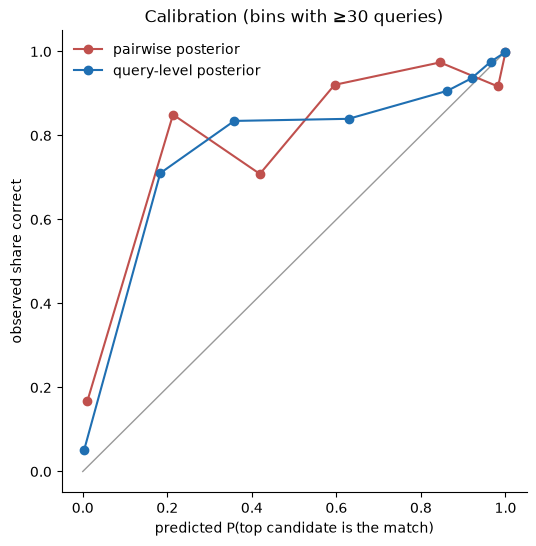

In [13]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], color="#999", lw=1, zorder=0)
for col, label, color in [("p_pairwise", "pairwise posterior", "#c0504d"), ("p", "query-level posterior", "#1f6fb2")]:
    c = cal[col][cal[col].n >= 30]
    ax.plot(c.predicted, c.observed, marker="o", label=label, color=color)
ax.set_xlabel("predicted P(top candidate is the match)")
ax.set_ylabel("observed share correct")
ax.set_title("Calibration (bins with ≥30 queries)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

The estimate of rho comes out below the truth (0.80 against 0.85) by roughly
the share of true matches blocking never found. The model cannot see matches
it was never shown, so this is expected rather than a bug.

Now compare the two columns in the calibration table, and the two lines in the
plot. `predicted` is the average probability the model assigned in that band;
`observed` is how often it was actually right. On a perfectly calibrated model
they would be equal.

Neither version is calibrated in the middle — both are underconfident there.
What differs is **where the queries end up**. The pairwise version strands
~3,400 queries in the uncertain 0.1-0.9 band; the query-level version leaves
~2,200 and pushes the rest up into >= 0.95, where 97.6% of the 0.95-0.99 band
turns out correct. In practice that raises the auto-accept rate at a 0.95
threshold from 63% to 72%, costing 0.2 points of precision (99.8% -> 99.6%).

The query-level posterior is still clearly underconfident between 0.1 and 0.7
(predicted 0.18, observed 0.71; predicted 0.36, observed 0.84). Those queries
are mostly two kinds: "name matches exactly, address disagrees" (moves and
franchises) and "address only" (shared buildings). Leftover correlation
between attributes and the crude background factor account for the gap. If
that band matters to you, a few hundred labels plus isotonic regression on `p`
will fix it far more cheaply than improving the model.

## 9. Decisions

The ranked list with probabilities is the real output. When a single answer is
needed, take the top candidate and apply two thresholds: accept at >= 0.95,
send to review at >= 0.5, otherwise call it no match. Queries with no
candidates at all are no matches by definition.

No "is the top candidate far enough ahead of the second?" rule is needed,
because the query-level posterior already splits probability between close
candidates — a tie cannot produce a high top probability.

In [14]:
D = mt.decide(P, accept_p=0.95, review_p=0.5)
D = T.rename(columns={"query_id": "qid", "entity_id": "true_eid"}).merge(D, on="qid", how="left")
D["decision"] = D.decision.fillna("no_match")
D["outcome"] = np.select(
    [D.true_eid.isna() & (D.decision == "no_match"), D.true_eid.isna(),
     D.eid == D.true_eid, D.decision == "no_match"],
    ["correct reject", "unknown matched", "right entity", "missed"], "wrong entity")
print(pd.crosstab(D.decision, D.outcome, margins=True))
acc = D[D.decision == "accept"]
print(f"\nauto-accept rate {len(acc) / len(D):.1%}, precision {(acc.eid == acc.true_eid).mean():.2%}")
print(f"review rate {(D.decision == 'review').mean():.1%}")

outcome   correct reject  missed  right entity  unknown matched  wrong entity    All
decision                                                                            
accept                 0       0         14334               48            14  14396
no_match            2865     510          1070                0             0   4445
review                 0       0          1017               97            45   1159
All                 2865     510         16421              145            59  20000

auto-accept rate 72.0%, precision 99.57%
review rate 5.8%


Both thresholds are policy, not statistics. The sweep below is how to pick the
accept cutoff from a precision target instead of by feel.

In [15]:
d = top_per_query(P, "p")
sweep = [{"threshold": t, "auto_accept_rate": (d.p >= t).mean(), "precision": d[d.p >= t].correct.mean()}
         for t in [0.5, 0.8, 0.9, 0.95, 0.99, 0.999]]
pd.DataFrame(sweep).round(4)

,threshold,auto_accept_rate,precision
0,0.500,0.7778,0.9869
1,0.800,0.7484,0.9927
2,0.900,0.7222,0.9955
3,0.950,0.7198,0.9957
4,0.990,0.6288,0.9986
5,0.999,0.6246,0.9986


### Where it fails

The flags in `truth.csv` record what the generator did to each query, so we
can break the results down by failure mode rather than looking at one average.

In [16]:
seg = D.assign(segment=np.select([D.true_eid.isna(), D.moved, D.rebranded, D.contaminated],
                                 ["unknown entity", "moved", "rebranded", "contaminated phone"], "other known"))
seg["accepted_wrong"] = (seg.decision == "accept") & seg.outcome.isin(["wrong entity", "unknown matched"])
seg.groupby("segment").agg(n=("qid", "size"),
                           accepted=("decision", lambda s: (s == "accept").mean()),
                           review=("decision", lambda s: (s == "review").mean()),
                           accepted_wrong=("accepted_wrong", "mean")).round(3)

,n,accepted,review,accepted_wrong
segment,,,,
contaminated phone,189,0.767,0.153,0.000
moved,1731,0.432,0.266,0.001
other known,14769,0.903,0.038,0.001
rebranded,301,0.395,0.040,0.003
unknown entity,3010,0.016,0.032,0.016


- **Rebranded** (the name changed and the old one is still in the table):
  without a second attribute to go on these are unrecoverable. What matters is
  that they come out as `no_match` rather than as a confident wrong answer.
- **Moved**: address and phone disagree together, so these lean entirely on
  the name, and they make up much of the review queue.
- **Unknown companies** (not in the table at all): 1.6% are auto-accepted, and
  those 48 queries are most of the 62 wrong accepts in the whole run. They are
  same-name or same-building hard negatives. The dominant failure of this
  system is not picking the wrong company — it is failing to say "not in the
  table". If false accepts are expensive, that is where labeling effort pays.

## What to take away

1. **Estimate `u` from pairs you know are non-matches** — distinct companies
   in a deduplicated table — not from random query pairs. The contamination in
   random pairs is the same size as the quantity being measured.
2. **Never run EM over a blocked candidate set with the blocking attribute in
   the model.** Run one round per blocking rule and leave that rule's
   attribute out.
3. **Term frequency needs the `count - 1` correction and a floor.** Without
   them, unique values are under-weighted and shared ones over-weighted.
4. **Normalize probabilities per query.** Scoring each pair in isolation
   cannot represent "it is one of these two", and reports both at 0.99.
5. **Check the model against even a few hundred labels.** Every failure above
   is invisible without them, and the independence assumption — a move changes
   address and phone together — shows up in both `m` and the calibration.

## Applying this to your own data

`mt.normalize` expects long format: `(id, attr_type, value)`. Edit
`NORMALIZERS` for how your attribute types should be cleaned and `COMPARISONS`
for their levels and thresholds. Then pick blocking rules for the EM rounds so
that every attribute is estimated in at least one round where it was not the
blocking key.